# 18 · M1.3b · CPER 2020–2023: per-season predictive gains (descriptive)

**Status: descriptive, exploratory.**
- Notebook 17 found the CRT sampler *not suitable* for exploratory testing on the real features, by its declared rule: within-day persistence is under-simulated, and the hour-dependent scale and heavy tails of the residuals are missing.
- As declared in plan §9 (2026-11-01), **no zero-information p-value is computed** here, neither CRT nor shift. The shift test is not valid at CPER's persistence either (notebooks 11 and 14).
- Gains are reported per season, without intervals: the season-cluster interval failed validation (notebook 16, A4).

**Declared before this notebook was first executed.**
- **Primary.** `suite.pipeline` with the notebook 16 protocol on 2020–2023 (seasons = years):
  - the context is chosen per held-out year among L3 / L4 / S / S4, on training rows only;
  - V is clipped to its training range, with robust Gaussian scoring and common support on (hour, T);
  - the label is D_h = T_asp − Td, and the visual input is the nine frozen features.
- **Reported.**
  - *Per-season gain* G_s: the held-out mean log-score gain of q(D | V, C) over q(D | C) in year s, fitted on the other three years, in nats per row.
  - The chosen contexts and the share of rows outside common support.
  - *Chronological gain* G: fit on 2020–2022, evaluate on 2023, a year that informed the method.
  - *Repair diagnostic* (τ = 0.002 nats per row), on the chosen and on the misspecified L1 context. The context-only challenger, which failed validation (A6), is reported but not interpreted.
- **Sensitivities** (per season, same protocol):
  - the context forced to each candidate;
  - the probe label D_probe = T_probe − Td;
  - E2_illum (clear-sky index K in C; rows with solar elevation > 10°) beside E2 on the same rows;
  - the acquisition-only control (log exposure as the only input on the visual side, SCI level `e2_acq_control`);
  - removal of rows with RH_implied ≥ 98.3 %, both as a frozen deletion and as a full refit (D-066).
- **Interpretation rules.**
  - No statement that moisture information beyond C exists or is absent. Gains are predictive differences for this design, not E2 (statistical note §2).
  - A positive gain with a repair flag is read as possible context repair.
  - A gain that the acquisition-only control reproduces is read as an exposure or illumination pathway, not as moisture information.

In [1]:
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

from visual_hygrometry import data, features, suite

warnings.filterwarnings('ignore', message='Mean of empty slice')
plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (11, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 4)
OFF, LAT, LON, YEARS, TAU = -7, suite.LAT, suite.LON, [2020, 2021, 2022, 2023], 0.002
U = pd.read_csv(data.ROOT / 'data' / 'interim' / 'm13_CPER.csv', parse_dates=['utc'])  # notebook 17's usable rows
VIS = [n for n in features.NAMES if not ((U.groupby('year').qc_sky_clip.median() > .2).any() and n.startswith('vis_sky'))]
loc = (U.utc + pd.Timedelta(hours=OFF)).dt.tz_localize(None)
R0 = pd.DataFrame({'year': U.year - 2020, 'doy': loc.dt.day_of_year, 'hour_local': loc.dt.hour + loc.dt.minute / 60,
                   'day': (loc.dt.floor('D') - pd.Timestamp('2020-01-01')).dt.days, 'temp_cond_c': U.t_asp, 'd_ref_k': U.D_h,
                   'clearsky_k': U.K, 'calib_exposure': np.log(U.exposure)})
R0 = pd.concat([R0, U[VIS], data.fourier(R0.hour_local, 24, 2, 'hour'), data.solar(R0.doy, R0.hour_local, LAT, LON, OFF)], axis=1).assign(ref_sensor_id='TRAAT', cond_sensor_id='TRAAT')
W = {'vis': VIS, 'shared_sensor': True, 'null_tests': False}
print(f'{len(R0)} rows, {R0.day.nunique()} days; visual features: {VIS}')

4817 rows, 364 days; visual features: ['vis_sky_lum', 'vis_sky_br', 'vis_far_contrast', 'vis_near_contrast', 'vis_contrast_ratio', 'vis_far_sat', 'vis_near_gcc', 'vis_near_dark', 'vis_far_sharp']


## 1 · Primary: per-season gains

In [2]:
P = suite.pipeline(R0, W)
pd.DataFrame({'rows': R0.groupby('year').size().to_numpy(), 'held-out gain G_s (nats/row)': P['seas_G'], 'context chosen when held out': P['chosen']}, index=pd.Index(YEARS, name='season'))

,rows,held-out gain G_s (nats/row),context chosen when held out
season,,,
2020,1225,0.0198,S
2021,1166,0.0224,S
2022,1220,-0.0254,S
2023,1206,0.0733,S4


In [3]:
print(f"mean over seasons {np.mean(P['seas_G']):+.4f}; row-weighted {P['est']:+.4f} nats/row; rows outside common support {P['excluded']:.3f}")
print(f"chronological gain (fit 2020–2022, evaluate 2023, a year that informed the method): {P['G']:+.4f} nats/row")
print(f"repair diagnostic lower bound: chosen context {P['repair_lb']:+.4f} (flag at τ = {TAU}: {P['repair_lb'] > TAU}); misspecified L1 {P['repair_lb_L1']:+.4f} (flag: {P['repair_lb_L1'] > TAU})")
print(f"context-only challenger lower bound (failed validation, not interpreted): chosen {P['audit_lb']:+.4f}, L1 {P['audit_lb_L1']:+.4f}")

mean over seasons +0.0225; row-weighted +0.0226 nats/row; rows outside common support 0.011
chronological gain (fit 2020–2022, evaluate 2023, a year that informed the method): +0.0733 nats/row
repair diagnostic lower bound: chosen context -0.0237 (flag at τ = 0.002: False); misspecified L1 -0.0405 (flag: False)
context-only challenger lower bound (failed validation, not interpreted): chosen -0.0368, L1 -0.0589


## 2 · Sensitivities

In [4]:
sun = (R0.solar_elev_deg > 10).to_numpy()
wet = (U.rh_implied >= 98.3).to_numpy()
RUNS = {f'context forced to {lv}': (R0, W, lv) for lv in suite.CANDIDATES}
RUNS |= {'label D_probe': (R0.assign(d_ref_k=(U.t_probe - U.td).to_numpy(), ref_sensor_id='HMP155'), W, None),
         'E2, rows with elevation > 10°': (R0[sun].reset_index(drop=True), W, None),
         'E2_illum, rows with elevation > 10°': (R0[sun].reset_index(drop=True), W | {'illum': True}, None),
         'acquisition-only control (log exposure)': (R0, W | {'vis': ['calib_exposure'], 'level': 'e2_acq_control'}, None),
         'RH_implied ≥ 98.3 % removed, refit': (R0[~wet].reset_index(drop=True), W, None)}
res = dict(zip(RUNS, Parallel(n_jobs=len(RUNS), max_nbytes=None)(delayed(suite.pipeline)(d, w, full=False, force=f) for d, w, f in RUNS.values())))
frozen = pd.Series(P['d']).where(~wet).groupby(R0.year).mean().to_numpy()
tab = pd.DataFrame({'primary': P['seas_G']} | {k: r['seas_G'] for k, r in res.items()} | {'RH_implied ≥ 98.3 % removed, frozen': frozen}, index=YEARS).T
tab['mean over seasons'] = tab[YEARS].mean(axis=1)
tab['2023 chronological'] = pd.Series({'primary': P['G']} | {k: r['G'] for k, r in res.items()})
tab['rows'] = pd.Series({'primary': len(R0)} | {k: len(d) for k, (d, _, _) in RUNS.items()} | {'RH_implied ≥ 98.3 % removed, frozen': int((~wet).sum())})
tab

,2020,2021,2022,2023,mean over seasons,2023 chronological,rows
primary,0.0198,0.0224,-0.0254,0.0733,0.0225,0.0733,4817
context forced to L3,0.0197,0.0230,-0.0226,0.0736,0.0234,0.0736,4817
context forced to L4,0.0201,0.0234,-0.0217,0.0751,0.0242,0.0751,4817
context forced to S,0.0198,0.0224,-0.0254,0.0722,0.0222,0.0722,4817
context forced to S4,0.0202,0.0227,-0.0253,0.0733,0.0227,0.0733,4817
label D_probe,0.0178,0.0188,-0.0224,0.0725,0.0217,0.0725,4817
"E2, rows with elevation > 10°",0.0224,0.0204,-0.0205,0.0299,0.0130,0.0299,4475
"E2_illum, rows with elevation > 10°",0.0257,0.0188,-0.0177,0.0560,0.0207,0.0560,4475
acquisition-only control (log exposure),-0.0039,0.0118,0.0112,0.0168,0.0090,0.0168,4817
"RH_implied ≥ 98.3 % removed, refit",0.0135,0.0030,-0.0557,0.0712,0.0080,0.0712,4797


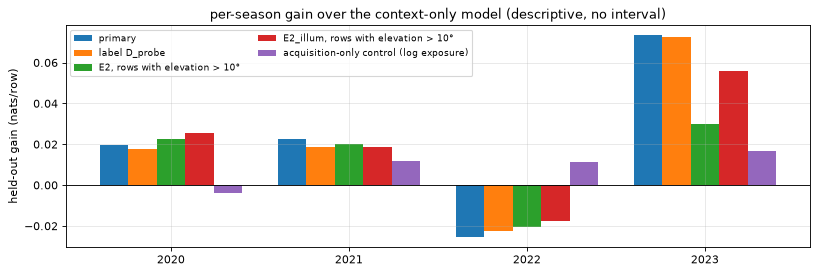

In [5]:
fig, ax = plt.subplots(figsize=(12, 3.6))
show = ['primary', 'label D_probe', 'E2, rows with elevation > 10°', 'E2_illum, rows with elevation > 10°', 'acquisition-only control (log exposure)']
w = .8 / len(show)
for i, k in enumerate(show): ax.bar(np.arange(4) + i * w, tab.loc[k, YEARS].to_numpy(float), w, label=k)
ax.axhline(0, color='k', lw=.8)
ax.set(xticks=np.arange(4) + .4 - w / 2, xticklabels=YEARS, ylabel='held-out gain (nats/row)', title='per-season gain over the context-only model (descriptive, no interval)')
ax.legend(fontsize=8, ncol=2);

## 3 · Reading

**Per-season gains (nats/row, held out by year, descriptive).**

| | 2020 | 2021 | 2022 | 2023 |
|---|---|---|---|---|
| G_s | +0.020 | +0.022 | **−0.025** | +0.073 |

- The mean over seasons is +0.023. The sign is not consistent: 2022 loses, and 2023 gains about three times as much as 2020–2021.
- With four seasons and no validated interval, this spread cannot be separated from between-season variation in the true gain. Neither "information beyond C" nor its absence follows.
- The chronological gain on 2023 (+0.073) is the same split as the held-out 2023 fold, because both fit on 2020–2022. 2023 also informed the method, so it is not an independent check.
- **2022 stands out.** Its near-field greenness hardly declines over the summer (notebook 17 §5), unlike in the other years. A joint model fitted on the other years may therefore transfer a greenness–D relation that does not hold in 2022. This is a plausible reading, not tested here.

**Robustness.**
- **Context.** Forcing any candidate (L3, L4, S, S4) moves each G_s by ≤ 0.004. The choice between the clock-time and solar contexts does not drive the result.
- **Label.** The probe label D_probe gives the same pattern (+0.018, +0.019, −0.022, +0.073).
- **Repair diagnostic.** No flag: the lower bounds are −0.024 on the chosen context and −0.041 on L1. There is no sign that the image repairs a missing function of C. The challenger's bounds are also negative, but it failed validation and is not interpreted.
- **Refit instability.** Removing the 20 rows with RH_implied ≥ 98.3 % and refitting changes G_s by −0.006 (2020), −0.019 (2021), −0.030 (2022) and −0.002 (2023), although frozen deletion of the same rows changes it by at most 0.002. As with HARV in notebook 12, the penalty and capacity choices respond to a handful of rows, so single-season gains of this size are fragile.

**Pathways.**
- **Acquisition-only control.** Log exposure alone, in place of the image features, gains −0.004, +0.012, +0.011 and +0.017. Part of the predictive signal is available from the auto-exposure state, which tracks cloud and illumination. In 2022 exposure gains while the features lose.
- **Low sun.** On rows with solar elevation > 10° the E2 gain in 2023 falls from +0.073 to +0.030; the other years change by ≤ 0.005. Much of 2023's gain therefore comes from its low-sun rows (342 such rows across the four seasons, at dawn and dusk), where the image is dominated by illumination geometry and dew or low cloud are possible.
- **E2_illum.** On the same rows, adding the clear-sky index to C *raises* the 2023 gain to +0.056 and leaves the other years within 0.004. The image's gain in 2023 is therefore not explained by cloudiness as measured by K.

**What this supports.**
- Predictive gains of order 0.02 nats/row appear in three of four CPER seasons. They are fragile to refitting, inconsistent in sign, and partly shared with the exposure state.
- Without a valid null generator (notebook 17) and without a valid interval (notebook 16), they are descriptive only. They are not evidence about E2 and not a moisture-optics signal.